# PayGuard — SHAP Explainability on the Champion Model

Champion: **XGBoost (SMOTE)** — F1 0.7579, precision 0.7200, recall 0.8000, ROC-AUC 0.9843.

## Goal of this notebook

1. Build a SHAP explainer for the champion model.
2. Compare SHAP global feature importance with the model's `feature_importances_`.
3. Explain individual flagged transactions using per-feature SHAP values, supporting the dashboard's explanations.
4. Package a reusable `explain_transaction()` function for future integration with the backend API.

> **Note:** PayGuard is evaluated on synthetic PaySim-derived data adapted to a UPI-style schema. Results do not establish real-world fraud-detection performance.

If SHAP is not already installed:

```bash
pip install shap

In [1]:
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

bundle = joblib.load("../data/processed/train_test_variants.pkl")
champion_model = joblib.load("../models/xgboost.pkl")

X_test_scaled = bundle["X_test_scaled"]
y_test = bundle["y_test"]
feature_cols = bundle["feature_cols"]
scaler = bundle["scaler"]

print("Champion model loaded:", type(champion_model).__name__)
print("Test set:", X_test_scaled.shape)

Champion model loaded: XGBClassifier
Test set: (16000, 21)


## 1. Build the SHAP explainer

`TreeExplainer` is the fast, exact SHAP method for tree-based models (works for XGBoost, Random Forest, LightGBM, etc.) — much faster than the general-purpose `KernelExplainer`, which we'd need for a non-tree model like Logistic Regression or an SVM.

In [2]:
explainer = shap.TreeExplainer(champion_model)
shap_values = explainer.shap_values(X_test_scaled)

print("SHAP values shape:", shap_values.shape, "(rows x features, one SHAP value per feature per row)")

SHAP values shape: (16000, 21) (rows x features, one SHAP value per feature per row)


## 2. Global feature importance (sanity check against `feature_importances_`)

Mean absolute SHAP value per feature — should broadly agree with the XGBoost feature importance table from notebook 4c, since they're both measuring "how much does this feature matter," just computed differently.

In [3]:
mean_abs_shap = pd.DataFrame({
    "feature": feature_cols,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

mean_abs_shap

,feature,mean_abs_shap
10,hour_of_day,2.715846
13,receiver_balance_delta,1.162790
0,amount,0.967549
2,sender_balance_before,0.885601
12,sender_balance_error,0.791137
14,balance_ratio,0.727043
3,sender_balance_after,0.367549
16,mode_CASH_IN,0.312119
5,receiver_balance_after,0.291885
4,receiver_balance_before,0.254462


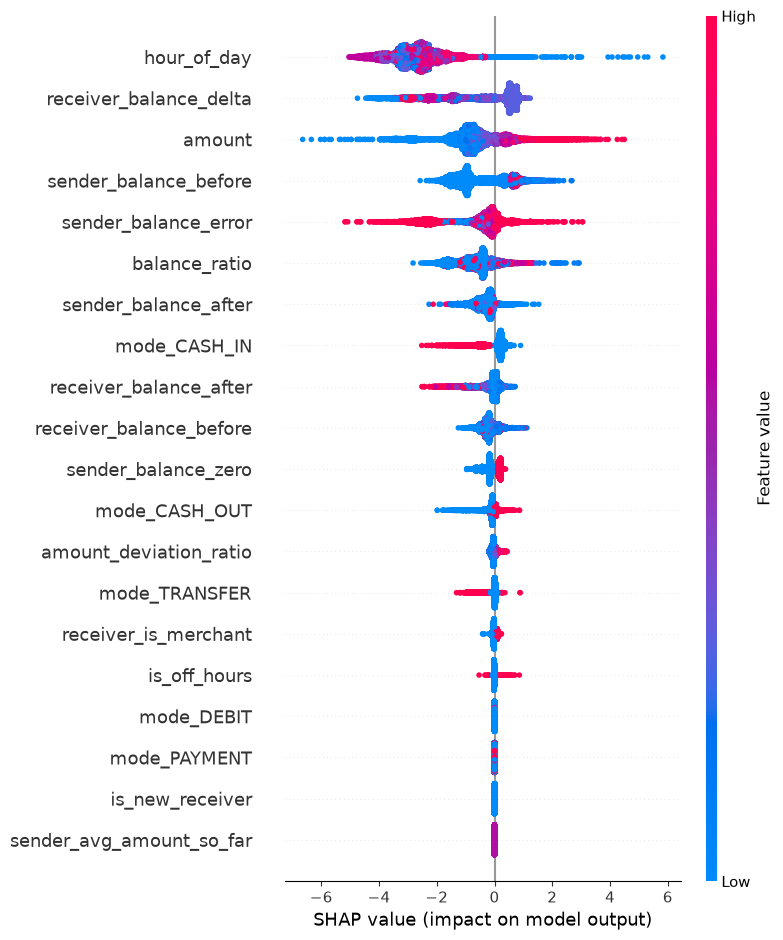

In [4]:
shap.summary_plot(shap_values, X_test_scaled, feature_names=feature_cols, show=False)
plt.tight_layout()
plt.savefig("../models/shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Explain individual transactions

Pick a couple of actual fraud cases and one legitimate transaction from the test set, and show the per-feature breakdown — this is exactly what the dashboard's "why was this flagged" chart will show.

In [5]:
def explain_row(row_position, top_n=6):
    """Print a human-readable SHAP breakdown for one row (by position) in X_test_scaled."""
    row_shap = shap_values[row_position]
    row_features = X_test_scaled.iloc[row_position]
    true_label = y_test.iloc[row_position]
    pred_proba = champion_model.predict_proba(X_test_scaled.iloc[[row_position]])[0, 1]

    contrib_df = pd.DataFrame({
        "feature": feature_cols,
        "value_scaled": row_features.values,
        "shap_contribution": row_shap,
    }).sort_values("shap_contribution", key=abs, ascending=False).head(top_n)

    print(f"True label: {'FRAUD' if true_label == 1 else 'Not Fraud'}  |  "
          f"Predicted risk score: {pred_proba:.4f}")
    print(f"\nTop {top_n} contributing features:")
    print(contrib_df.to_string(index=False))
    return contrib_df


# find a couple of actual fraud rows and one non-fraud row in the test set
fraud_positions = np.where(y_test.values == 1)[0][:2]
nonfraud_position = np.where(y_test.values == 0)[0][0]

print("=" * 60)
print("EXAMPLE 1: An actual fraud case")
print("=" * 60)
explain_row(fraud_positions[0])

EXAMPLE 1: An actual fraud case
True label: FRAUD  |  Predicted risk score: 0.0725

Top 6 contributing features:
               feature  value_scaled  shap_contribution
         balance_ratio     -0.588185          -1.365544
                amount     -0.239512          -1.148736
          is_off_hours     11.689072           0.549835
          mode_CASH_IN      1.889218          -0.529579
receiver_balance_after     -0.308986          -0.492114
 sender_balance_before      1.824982           0.464488


,feature,value_scaled,shap_contribution
14,balance_ratio,-0.588185,-1.365544
0,amount,-0.239512,-1.148736
11,is_off_hours,11.689072,0.549835
16,mode_CASH_IN,1.889218,-0.529579
5,receiver_balance_after,-0.308986,-0.492114
2,sender_balance_before,1.824982,0.464488


In [6]:
print("=" * 60)
print("EXAMPLE 2: Another actual fraud case")
print("=" * 60)
explain_row(fraud_positions[1])

EXAMPLE 2: Another actual fraud case
True label: FRAUD  |  Predicted risk score: 0.8013

Top 6 contributing features:
               feature  value_scaled  shap_contribution
           hour_of_day      0.158503          -2.644306
         balance_ratio     -0.311944           2.178065
  sender_balance_error      0.295638           1.670495
receiver_balance_delta     -0.103344           0.651451
  sender_balance_after     -0.292304           0.558350
                amount     -0.218896          -0.486187


,feature,value_scaled,shap_contribution
10,hour_of_day,0.158503,-2.644306
14,balance_ratio,-0.311944,2.178065
12,sender_balance_error,0.295638,1.670495
13,receiver_balance_delta,-0.103344,0.651451
3,sender_balance_after,-0.292304,0.558350
0,amount,-0.218896,-0.486187


In [7]:
print("=" * 60)
print("EXAMPLE 3: A legitimate transaction (for contrast)")
print("=" * 60)
explain_row(nonfraud_position)

EXAMPLE 3: A legitimate transaction (for contrast)
True label: Not Fraud  |  Predicted risk score: 0.0090

Top 6 contributing features:
                feature  value_scaled  shap_contribution
            hour_of_day     -0.998609          -2.903534
                 amount     -0.250113          -1.333288
  sender_balance_before     -0.288394          -0.969345
 receiver_balance_delta     -0.137860           0.757066
          balance_ratio     -0.589029          -0.428544
receiver_balance_before     -0.314918          -0.279031


,feature,value_scaled,shap_contribution
10,hour_of_day,-0.998609,-2.903534
0,amount,-0.250113,-1.333288
2,sender_balance_before,-0.288394,-0.969345
13,receiver_balance_delta,-0.137860,0.757066
14,balance_ratio,-0.589029,-0.428544
4,receiver_balance_before,-0.314918,-0.279031


## 4. Package the reusable `explain_transaction()` function

This is the function the backend API will actually call. It takes a **raw feature row** (already engineered and scaled — same shape as `X_test_scaled`), and returns a clean dict: risk score, fraud label, and the top contributing features with plain-language direction ("pushed toward fraud" / "pushed toward normal").

**Important scope note for the backend (Person D's part):** this function assumes the incoming transaction has *already* been through the same feature engineering as notebook 3 (behavioral features like `sender_avg_amount_so_far`, `is_new_receiver`, etc.). For a brand-new transaction arriving at the live API, the backend will need to look up the sender's transaction history from PostgreSQL to compute those features before calling this function — this notebook only handles the model + explanation half of the pipeline.

In [8]:
def explain_transaction(feature_row: pd.Series, threshold: float = 0.5, top_n: int = 5) -> dict:
    """
    feature_row: a pandas Series with the same columns as X_test_scaled (already engineered + scaled)
    Returns a dict ready to be serialized as JSON by the backend API.
    """
    row_df = feature_row.to_frame().T
    row_df = row_df[feature_cols]  # enforce correct column order

    risk_score = float(champion_model.predict_proba(row_df)[0, 1])
    label = "fraud" if risk_score >= threshold else "not_fraud"

    row_shap = explainer.shap_values(row_df)[0]
    contrib_df = pd.DataFrame({
        "feature": feature_cols,
        "contribution": row_shap,
    })
    contrib_df["direction"] = np.where(contrib_df["contribution"] > 0, "toward_fraud", "toward_normal")
    top_contributors = (
        contrib_df.reindex(contrib_df["contribution"].abs().sort_values(ascending=False).index)
        .head(top_n)
        .to_dict(orient="records")
    )

    return {
        "risk_score": round(risk_score, 4),
        "label": label,
        "top_contributors": [
            {
                "feature": c["feature"],
                "contribution": round(c["contribution"], 4),
                "direction": c["direction"],
            }
            for c in top_contributors
        ],
    }


# quick test on one of the fraud rows from above
example_output = explain_transaction(X_test_scaled.iloc[fraud_positions[0]])
import json
print(json.dumps(example_output, indent=2))

{
  "risk_score": 0.0725,
  "label": "not_fraud",
  "top_contributors": [
    {
      "feature": "balance_ratio",
      "contribution": -1.3655,
      "direction": "toward_normal"
    },
    {
      "feature": "amount",
      "contribution": -1.1487,
      "direction": "toward_normal"
    },
    {
      "feature": "is_off_hours",
      "contribution": 0.5498,
      "direction": "toward_fraud"
    },
    {
      "feature": "mode_CASH_IN",
      "contribution": -0.5296,
      "direction": "toward_normal"
    },
    {
      "feature": "receiver_balance_after",
      "contribution": -0.4921,
      "direction": "toward_normal"
    }
  ]
}


## 5. Save everything the backend needs

One bundle with the model, scaler, feature column order, and a note on the explainer (SHAP's `TreeExplainer` is cheap to rebuild from the loaded model, so we rebuild it at serving time in the backend rather than pickling the explainer object itself — avoids SHAP version-compatibility issues between training and serving environments).

In [9]:
inference_bundle = {
    "model": champion_model,
    "scaler": scaler,
    "feature_cols": feature_cols,
    "model_name": "XGBoost",
    "preprocessing_variant": "SMOTE",
    "decision_threshold": 0.5,
}

joblib.dump(inference_bundle, "../models/inference_bundle.pkl")
print("Saved ../models/inference_bundle.pkl")
print("\nThe backend will load this file, rebuild shap.TreeExplainer(bundle['model']) once at startup,")
print("and call explain_transaction()-style logic on each incoming (already feature-engineered) request.")

Saved ../models/inference_bundle.pkl

The backend will load this file, rebuild shap.TreeExplainer(bundle['model']) once at startup,
and call explain_transaction()-style logic on each incoming (already feature-engineered) request.


## Next: the backend (FastAPI + PostgreSQL)

With `inference_bundle.pkl` saved, the ML side of the project is functionally complete. Next step moves out of notebooks and into `backend/`: building the FastAPI service that loads this bundle, exposes a `/predict` endpoint, computes behavioral features for an incoming transaction from stored history, and calls the same explain logic built here.